nota_exame - aulas_participadas - horas_estudo

#Importando bibliotecas

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import statsmodels.api as sm

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/!dados/Analíse-Preditiva-Exercício/Base_Notas_v2.csv', index_col='id')
df.head()

,horas_estudo,aulas_participadas,nota_exame
id,,,
0,5.993428,8,76.119754
1,4.723471,11,60.929961
2,6.295377,12,81.731317
3,8.046060,7,82.699637
4,4.531693,5,70.662399


In [ ]:
df.isna().sum

<bound method DataFrame.sum of     horas_estudo  aulas_participadas  nota_exame
id                                              
0          False               False       False
1          False               False       False
2          False               False       False
3          False               False       False
4          False               False       False
5          False               False       False
6          False               False       False
7          False               False       False
8          False               False       False
9          False               False       False
10         False               False       False
11         False               False       False
12         False               False       False
13         False               False       False
14         False               False       False
15         False               False       False
16         False               False       False
17         False               False       False
18         False               False       False
19         False               False       False
20         False               False       False
21         False               False       False
22         False               False       False
23         False               False       False
24         False               False       False
25         False               False       False
26         False               False       False
27         False               False       False
28         False               False       False
29         False               False       False>

In [ ]:
df.describe().round(2)

,horas_estudo,aulas_participadas,nota_exame
count,30.00,30.00,30.00
mean,4.62,9.80,71.81
std,1.80,2.87,8.88
min,1.17,5.00,54.48
25%,3.82,8.00,66.41
50%,4.53,10.00,71.40
75%,5.72,12.00,78.10
max,8.16,14.00,89.47


In [ ]:
df.corr()

,horas_estudo,aulas_participadas,nota_exame
horas_estudo,1.000000,-0.136144,0.721178
aulas_participadas,-0.136144,1.000000,0.385559
nota_exame,0.721178,0.385559,1.000000


<Axes: xlabel='horas_estudo', ylabel='nota_exame'>

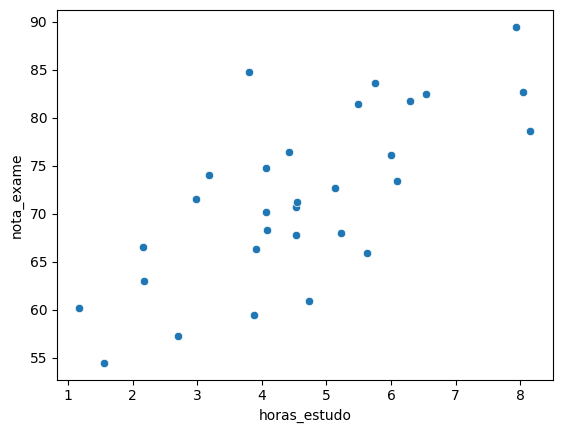

In [ ]:
sns.scatterplot(df, x='horas_estudo', y='nota_exame')

<Axes: xlabel='horas_estudo', ylabel='aulas_participadas'>

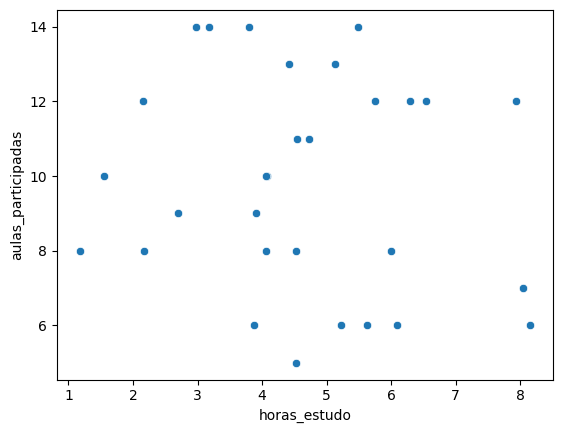

In [ ]:
sns.scatterplot(df, x='horas_estudo', y='aulas_participadas')

<Axes: >

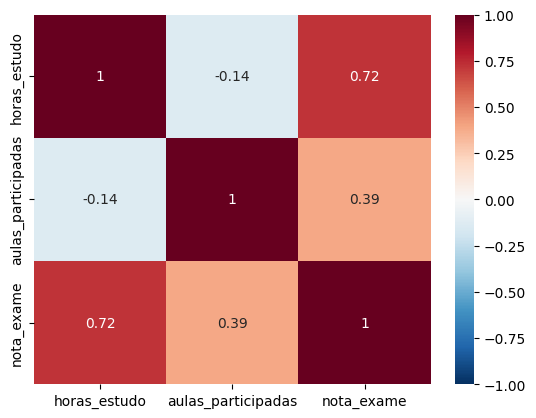

In [ ]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    #cmap= 'RdBu',
    #cmap= 'viridis',
    cmap= 'RdBu_r',
    annot=True
    )

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   horas_estudo        30 non-null     float64
 1   aulas_participadas  30 non-null     int64  
 2   nota_exame          30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 960.0 bytes


In [ ]:
y = df['horas_estudo']

df['intercepto'] = 1
x = df[['nota_exame', 'aulas_participadas','intercepto']]

In [ ]:
modelo = sm.OLS(y,x)

In [ ]:
resultado = modelo.fit()

In [ ]:
print(resultado.summary())
#Porcentagem = 72%
#nota_exame = 0.18 - 0.15
#intercepto = -5.62 - 5.88
#aulas_participadas = -0.31

                            OLS Regression Results                            
Dep. Variable:           horas_estudo   R-squared:                       0.722
Model:                            OLS   Adj. R-squared:                  0.701
Method:                 Least Squares   F-statistic:                     34.99
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           3.18e-08
Time:                        19:51:26   Log-Likelihood:                -40.512
No. Observations:                  30   AIC:                             87.02
Df Residuals:                      27   BIC:                             91.23
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
nota_exame             0.1843      0

In [ ]:
df['nova_nota'] = df['nota_exame'] * 0.15 + -5.88 + df['aulas_participadas'] * -0.31
display(df[['nota_exame','nova_nota']])

,nota_exame,nova_nota
id,,
0,76.119754,3.057963
1,60.929961,-0.150506
2,81.731317,2.659698
3,82.699637,4.354946
4,70.662399,3.169360
5,67.758906,1.803836
6,78.653234,4.057985
7,82.493253,2.773988
8,70.142780,2.161417


In [ ]:
df.head()

,horas_estudo,aulas_participadas,nota_exame,intercepto,nova_nota
id,,,,,
0,5.993428,8,76.119754,1,3.057963
1,4.723471,11,60.929961,1,-0.150506
2,6.295377,12,81.731317,1,2.659698
3,8.046060,7,82.699637,1,4.354946
4,4.531693,5,70.662399,1,3.169360


In [ ]:
df.query("aulas_participadas >= 14")

,horas_estudo,aulas_participadas,nota_exame,intercepto,nova_nota
id,,,,,
12,5.483925,14,81.462737,1,1.999411
16,2.974338,14,71.561862,1,0.514279
18,3.183952,14,74.072389,1,0.890858
28,3.798723,14,84.799914,1,2.499987


In [ ]:
df.query("nova_nota > 4")

,horas_estudo,aulas_participadas,nota_exame,intercepto,nova_nota
id,,,,,
3,8.046060,7,82.699637,1,4.354946
6,8.158426,6,78.653234,1,4.057985
